# 03 · Açıklanabilirlik: SHAP

**Amaç:** LightGBM modelinin kararlarını açıklamak.

- **Genel:** Model hangi değişkenlere dayanıyor?
- **Tekil:** Belirli bir hasar talebini *neden* şüpheli buldu (veya bulmadı)?

Sigortacılıkta açıklanabilirlik bir tercih değil, gerekliliktir: bir talebi incelemeye
gönderen hasar uzmanı "neden?" sorusunun cevabını bilmeli, şirket de kararını müşteriye
ve denetçiye açıklayabilmelidir.

**SHAP nedir?** Oyun teorisindeki Shapley değerlerine dayanır. Her tahmini, bir temel
değer ile her değişkenin katkısının toplamı olarak yazar:
`tahmin (log-odds) = temel değer + Σ SHAP(değişken)`. Pozitif SHAP değeri riski artırır,
negatif değer azaltır. Ağaç modelleri için TreeExplainer bu değerleri **tam** olarak
(yaklaşıklık olmadan) hesaplar.

> Bu defter, `02_modeling.ipynb` tarafından kaydedilen modeli kullanır. Önce onu çalıştırın.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.inspection import permutation_importance

from src import config, data, explain, plotting

warnings.filterwarnings("ignore", category=UserWarning)
plotting.set_style()
pd.set_option("display.width", 160)

model_path = config.MODELS_DIR / "lightgbm.joblib"
if not model_path.exists():
    raise FileNotFoundError("Run notebooks/02_modeling.ipynb first: it trains and saves the model.")
pipeline = joblib.load(model_path)

df = data.load_clean()
X_train, X_test, y_train, y_test = data.train_test(df)
test_proba = pipeline.predict_proba(X_test)[:, 1]

## 1. SHAP değerlerinin hesaplanması

Değerler **test seti** üzerinde hesaplanır: modelin görmediği taleplerde nasıl
davrandığını açıklamak istiyoruz.

In [2]:
shap_values, base_value = explain.shap_frame(pipeline, X_test)
reconstructed = explain.sigmoid(base_value + shap_values.sum(axis=1))
print(f"SHAP matrix: {shap_values.shape[0]:,} claims x {shap_values.shape[1]} features")
print(f"Base value (log-odds): {base_value:.3f}  ->  probability {explain.sigmoid(base_value):.1%}")
print(f"Additivity check, max |reconstructed - predicted probability|: "
      f"{np.abs(reconstructed - test_proba).max():.2e}")

SHAP matrix: 3,084 claims x 29 features
Base value (log-odds): -3.322  ->  probability 3.5%
Additivity check, max |reconstructed - predicted probability|: 6.11e-16


Toplanabilirlik kontrolü geçti: temel değer + SHAP değerlerinin toplamı, modelin
tahminini birebir veriyor. Temel değer ortalama log-odds'tur; sigmoid doğrusal olmadığı
için olasılık karşılığı ortalama tahmin edilen olasılıktan (%6) düşüktür.

## 2. Genel değişken önemi

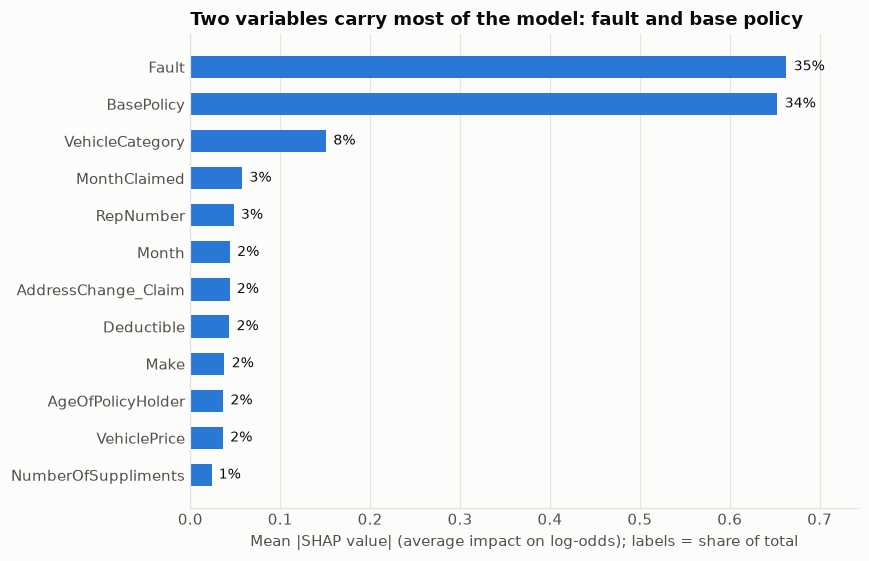

Fault + BasePolicy share of total mean |SHAP|: 68.7%
Top 3 share: 76.6%


In [3]:
importance = shap_values.abs().mean().sort_values(ascending=False)
importance_share = importance / importance.sum()
top = importance.head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.2))
bars = ax.barh(top.index, top.values, color=plotting.BLUE, height=0.6)
for bar, name in zip(bars, top.index):
    ax.text(bar.get_width() + 0.008, bar.get_y() + bar.get_height() / 2,
            f"{importance_share[name]:.0%}", va="center", color=plotting.INK, fontsize=9)
ax.set_xlim(0, top.max() * 1.12)
ax.set_xlabel("Mean |SHAP value| (average impact on log-odds); labels = share of total")
ax.set_title("Two variables carry most of the model: fault and base policy")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plotting.save_fig(fig, "09_shap_global_importance")
plt.show()

print(f"Fault + BasePolicy share of total mean |SHAP|: "
      f"{importance_share[['Fault', 'BasePolicy']].sum():.1%}")
print(f"Top 3 share: {importance_share.head(3).sum():.1%}")

Model, keşifsel analizin bulduğu yapıyı öğrenmiş: **kusur** ve **poliçe türü** toplam
etkinin yaklaşık üçte ikisini taşıyor; üçüncü sırada araç kategorisi var. Geri kalan
değişkenlerin her birinin katkısı küçük.

### 2.1 Yön ve dağılım (beeswarm)

Her nokta bir talep. Yatay eksen SHAP değeri (sağ = riski artırır). Renk, değişkenin
değerini gösterir (kırmızı = yüksek, mavi = düşük). Sırasız kategorik değişkenlerde
(ör. `BasePolicy`, `Make`) "yüksek/düşük" anlamsız olduğu için noktalar gridir.

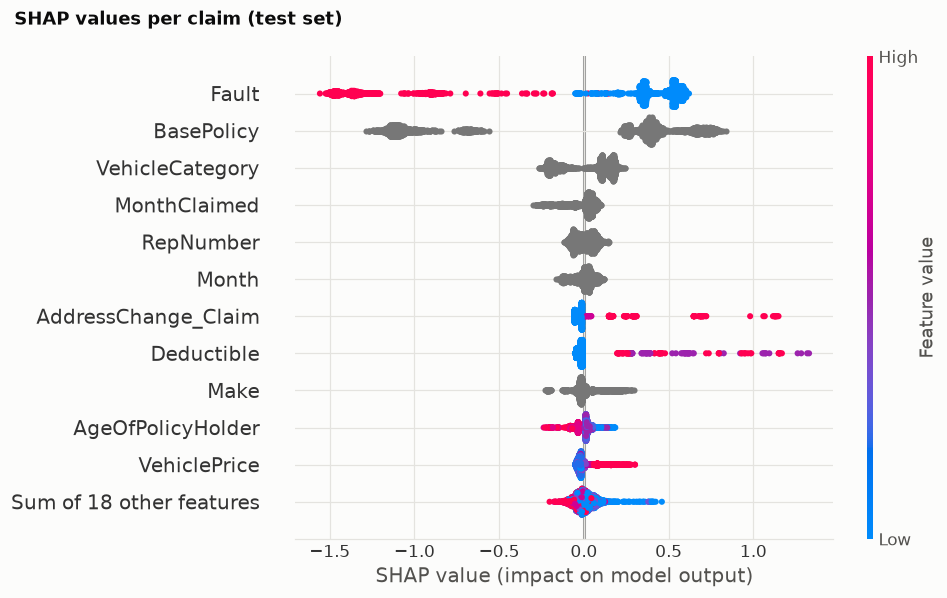

In [4]:
encoded_test = pipeline.named_steps["encode"].transform(X_test)
color_data = encoded_test.copy()
for col in config.NOMINAL_FEATURES:
    color_data[col] = np.nan            # no meaningful high/low for unordered categories
beeswarm = shap.Explanation(values=shap_values.to_numpy(), base_values=np.full(len(shap_values), base_value),
                            data=color_data.to_numpy(dtype=float), feature_names=list(shap_values.columns))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN colour columns are intended
    shap.plots.beeswarm(beeswarm, max_display=12, show=False, plot_size=(9, 5.5))
fig = plt.gcf()
fig.suptitle("SHAP values per claim (test set)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_fig(fig, "10_shap_beeswarm")
plt.show()

`Fault` satırında iki ayrı küme görülüyor: kusur üçüncü taraftaysa (kırmızı, `Fault = 1`)
SHAP değeri güçlü biçimde negatif; poliçe sahibindeyse pozitif.

### 2.2 Hangi düzey riski artırıyor?

Değişkenler kategorik olduğu için en okunaklı özet, her düzeyin ortalama SHAP değeridir.

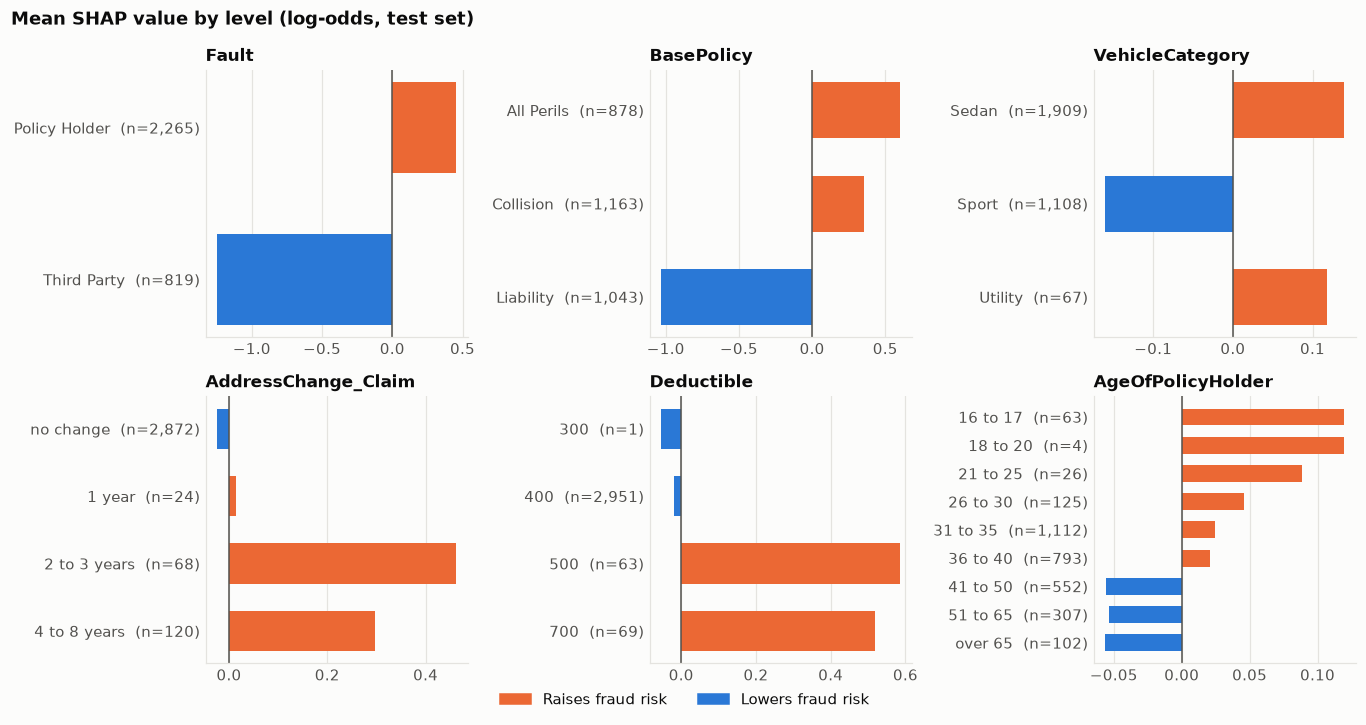

In [5]:
panel_features = ["Fault", "BasePolicy", "VehicleCategory", "AddressChange_Claim",
                  "Deductible", "AgeOfPolicyHolder"]
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6.4))
for ax, feature in zip(axes.ravel(), panel_features):
    effects = explain.level_effects(shap_values, X_test, feature, config.ORDINAL_FEATURES.get(feature))
    effects = effects.iloc[::-1]
    labels = [f"{lvl}  (n={n:,})" for lvl, n in zip(effects.index, effects["n"])]
    ax.barh(labels, effects["mean_shap"], height=0.6,
            color=[plotting.ORANGE if v > 0 else plotting.BLUE for v in effects["mean_shap"]])
    ax.axvline(0, color=plotting.INK_MUTED, linewidth=1)
    ax.set_title(feature, fontsize=11)
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=plotting.ORANGE), plt.Rectangle((0, 0), 1, 1, color=plotting.BLUE)]
fig.legend(handles, ["Raises fraud risk", "Lowers fraud risk"], loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Mean SHAP value by level (log-odds, test set)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save_fig(fig, "11_shap_by_level")
plt.show()

In [6]:
for feature in panel_features:
    print(explain.level_effects(shap_values, X_test, feature, config.ORDINAL_FEATURES.get(feature)).round(3), "\n")

               mean_shap     n
level                         
Policy Holder      0.452  2265
Third Party       -1.245   819 

            mean_shap     n
level                      
All Perils      0.599   878
Collision       0.356  1163
Liability      -1.029  1043 

         mean_shap     n
level                   
Sedan        0.139  1909
Sport       -0.160  1108
Utility      0.118    67 

              mean_shap     n
level                        
no change        -0.023  2872
1 year            0.014    24
2 to 3 years      0.461    68
4 to 8 years      0.296   120 

       mean_shap     n
level                 
300       -0.053     1
400       -0.021  2951
500        0.585    63
700        0.520    69 

          mean_shap     n
level                    
16 to 17      0.119    63
18 to 20      0.119     4
21 to 25      0.089    26
26 to 30      0.045   125
31 to 35      0.025  1112
36 to 40      0.021   793
41 to 50     -0.056   552
51 to 65     -0.053   307
over 65      -0.056   1

Yönler büyük ölçüde keşifsel analizle ve odds oranlarıyla tutarlı: poliçe sahibinin
kusuru, "All Perils" ve "Collision" poliçeleri, 2–3 yıl önceki adres değişikliği ve 500
muafiyet riski artırıyor; sorumluluk poliçesi ve üçüncü taraf kusuru azaltıyor.

### 2.3 Bir tutarsızlık ve nedeni

İki düzey keşifsel analizle **uyuşmuyor**: `Deductible = 700` ve
`AddressChange_Claim = 4 to 8 years` pozitif SHAP alıyor, oysa bu düzeylerde gerçek
sahtekârlık oranı ortalama düzeyde (defter 01). Model bu talepleri gerçekten fazla mı
puanlıyor? Eğitim setindeki kat dışı tahminlerle kontrol edelim.

In [7]:
oof = pd.read_csv(config.MODELS_DIR / "train_oof_predictions.csv", index_col="row_id")
calibration_check = X_train[["Deductible", "AddressChange_Claim"]].join(oof[["y", "oof_lightgbm"]])
for feature in ["Deductible", "AddressChange_Claim"]:
    print(calibration_check.groupby(feature)
          .agg(n=("y", "size"), actual_rate=("y", "mean"), mean_predicted=("oof_lightgbm", "mean"))
          .reindex(config.ORDINAL_FEATURES[feature]).round(3), "\n")

                n  actual_rate  mean_predicted
Deductible                                    
300             7        0.143           0.068
400         11886        0.057           0.058
500           200        0.205           0.150
700           242        0.066           0.076 

                         n  actual_rate  mean_predicted
AddressChange_Claim                                    
no change            11451        0.057           0.058
under 6 months           4        0.750           0.087
1 year                 146        0.062           0.059
2 to 3 years           223        0.197           0.144
4 to 8 years           511        0.049           0.068 



Tahminler bu düzeylerde gerçek orandan yalnızca 1–2 puan yüksek; SHAP değerlerinin ima
ettiği büyüklükte bir fazla puanlama yok. Tutarsızlık büyük ölçüde **tahminde değil,
katkının paylaştırılmasında**:

- Bu iki değişken sıralı (ordinal) kodlandı; sade model "muafiyet > 400" ve "adres
  değişikliği > 1 yıl" gibi tek bölmeler öğrenmiş, böylece komşu düzeyler aynı katkıyı
  almış.
- İki değişken güçlü biçimde ilişkili olduğu için (defter 01, bölüm 6.2) model birinin
  fazladan verdiği katkıyı diğeriyle dengeliyor.

**Ders:** İlişkili değişkenlerde SHAP değerleri tek tek değil **birlikte** okunmalı.
Bir hasar uzmanına "muafiyetiniz 700 olduğu için şüphelisiniz" demek yanlış olurdu.
Sonraki sürüm için not: bu iki değişkeni sırasız (nominal) kodlamak açıklamaları
sadeleştirir. Eğitim katlarında denendiğinde PR-AUC değişmediği için ve test seti
görüldükten sonra modeli değiştirmemek adına bu sürümde model olduğu gibi bırakıldı.

## 3. SHAP'i sorgulamak: permütasyon önemi

SHAP **modeli** açıklar, gerçeği değil. Model gürültüyü öğrenmişse SHAP o gürültüyü de
"önemli" gösterir. Bağımsız bir kontrol: her değişkeni test setinde rastgele karıştırıp
PR-AUC'nin ne kadar düştüğüne bakmak. Gerçekten bilgi taşıyan değişken karıştırılınca
performans düşer; gürültü karıştırılınca değişmez.

In [8]:
permutation = permutation_importance(pipeline, X_test, y_test, scoring="average_precision",
                                     n_repeats=30, random_state=config.RANDOM_STATE, n_jobs=2)
check = pd.DataFrame({
    "mean_abs_shap": importance,
    "shap_rank": importance.rank(ascending=False).astype(int),
    "pr_auc_drop": pd.Series(permutation.importances_mean, index=X_test.columns),
    "pr_auc_drop_std": pd.Series(permutation.importances_std, index=X_test.columns),
}).sort_values("mean_abs_shap", ascending=False)
check["clearly_useful"] = check["pr_auc_drop"] - 2 * check["pr_auc_drop_std"] > 0
check.head(14).round(4)

,mean_abs_shap,shap_rank,pr_auc_drop,pr_auc_drop_std,clearly_useful
Fault,0.6630,1,0.0806,0.0072,True
BasePolicy,0.6531,2,0.0727,0.0124,True
VehicleCategory,0.1511,3,0.0121,0.0061,False
MonthClaimed,0.0577,4,0.0074,0.0047,False
RepNumber,0.0482,5,-0.0060,0.0029,False
Month,0.0440,6,-0.0028,0.0036,False
AddressChange_Claim,0.0437,7,0.0241,0.0042,True
Deductible,0.0434,8,0.0204,0.0071,True
Make,0.0380,9,-0.0018,0.0039,False
AgeOfPolicyHolder,0.0366,10,0.0164,0.0051,True


In [9]:
useful = check.index[check["clearly_useful"]].tolist()
doubtful = check.head(10).index[~check.head(10)["clearly_useful"]].tolist()
print("Features whose shuffling clearly hurts test PR-AUC (drop > 2 std):", useful)
print("Features in the SHAP top 10 without a clear out-of-sample contribution:", doubtful)

Features whose shuffling clearly hurts test PR-AUC (drop > 2 std): ['Fault', 'BasePolicy', 'AddressChange_Claim', 'Deductible', 'AgeOfPolicyHolder', 'VehiclePrice', 'PastNumberOfClaims', 'AccidentArea']
Features in the SHAP top 10 without a clear out-of-sample contribution: ['VehicleCategory', 'MonthClaimed', 'RepNumber', 'Month', 'Make']


**Bu kontrol neden önemli?** Genel SHAP sıralamasında üst sıralarda görünen bazı
değişkenler (yukarıdaki ikinci liste) test setinde karıştırıldığında performansı
belirgin biçimde düşürmüyor (`VehicleCategory` sınırda; `BasePolicy` ile büyük ölçüde
aynı bilgiyi taşıyor). Örneğin `RepNumber` (hasar temsilcisi numarası) ve takvim
değişkenleri, keşifsel analizde sahtekârlıkla ilişkisiz veya çok zayıf ilişkili
bulunmuştu; modelin bunlara verdiği ağırlık büyük olasılıkla eğitim verisindeki
rastlantısal örüntülerdir.

Pratik sonuç: tekil açıklamalarda bu değişkenlerin katkısı bir hasar uzmanına
"kanıt" olarak sunulmamalı. Bir sonraki sürümde bu değişkenler çıkarılarak daha sade ve
savunulabilir bir model kurulabilir.

## 4. Tekil açıklamalar: model bu talebi neden şüpheli buldu?

Üç talep, üç farklı durum:

| Durum | Seçim kuralı |
|---|---|
| **A. Doğru alarm** | Gerçekten sahte olan ve en yüksek skoru alan talep |
| **B. Yanlış alarm** | Meşru olduğu hâlde en yüksek skoru alan talep |
| **C. Kaçırılan sahtekârlık** | Sahte olduğu hâlde en düşük skoru alan talep |

Talepler elle değil kuralla seçilir; böylece "işe yarayan örnekleri seçme" yanlılığı olmaz.

In [10]:
scored = pd.DataFrame({"actual": y_test, "probability": test_proba}, index=X_test.index)
cases = {
    "A. True alarm (actual: fraud)": scored[scored["actual"] == 1]["probability"].idxmax(),
    "B. False alarm (actual: legitimate)": scored[scored["actual"] == 0]["probability"].idxmax(),
    "C. Missed fraud (actual: fraud)": scored[scored["actual"] == 1]["probability"].idxmin(),
}
rank = scored["probability"].rank(ascending=False, method="min").astype(int)
for title, row_id in cases.items():
    print(f"{title:<38} row {row_id:>6}  probability {scored.at[row_id, 'probability']:.1%}  "
          f"(rank {rank[row_id]:,} of {len(scored):,} test claims)")

A. True alarm (actual: fraud)          row   2039  probability 47.4%  (rank 1 of 3,084 test claims)
B. False alarm (actual: legitimate)    row  13463  probability 31.2%  (rank 5 of 3,084 test claims)
C. Missed fraud (actual: fraud)        row  11674  probability 1.2%  (rank 2,467 of 3,084 test claims)


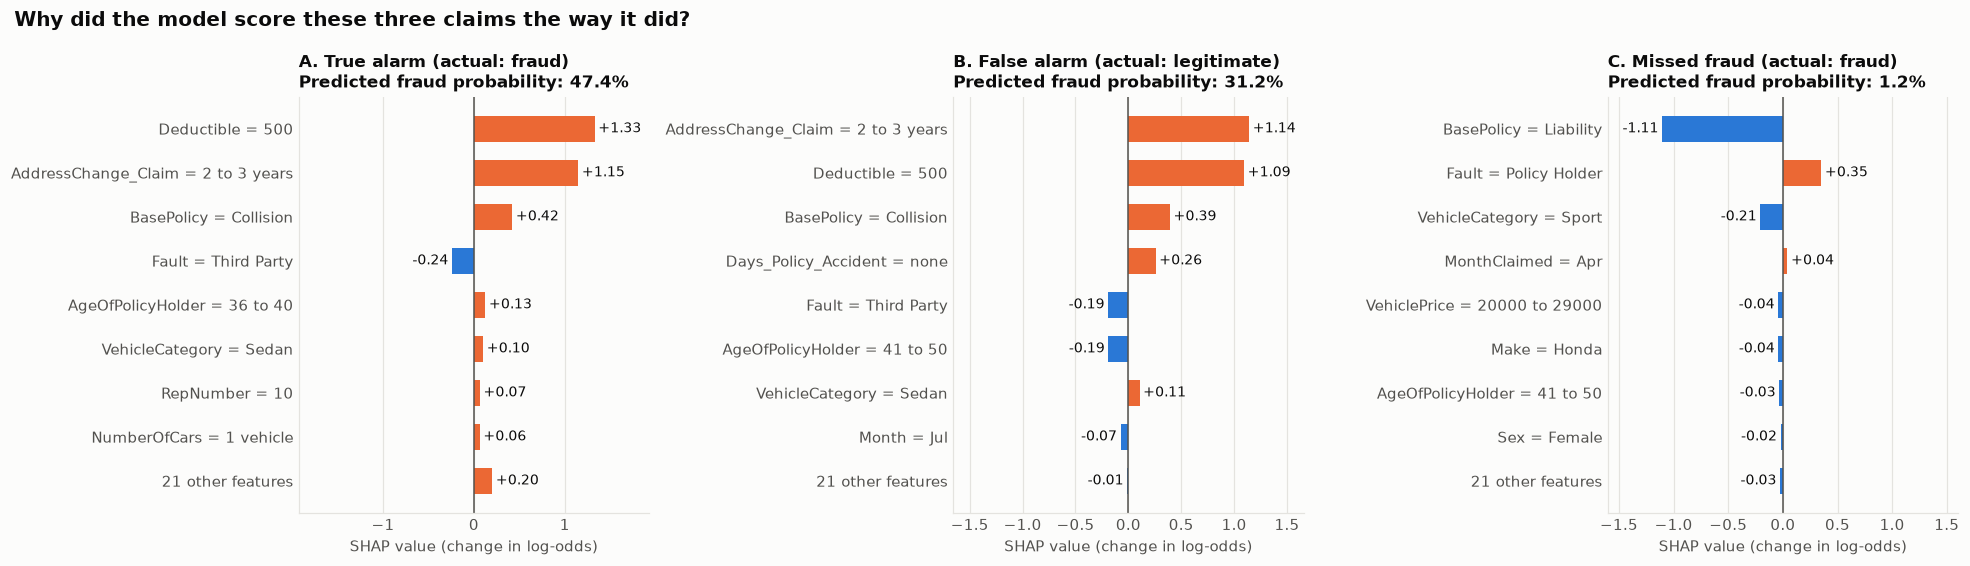

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, (title, row_id) in zip(axes, cases.items()):
    explain.plot_local(ax, shap_values.loc[row_id], X_test.loc[row_id], base_value, title)
fig.suptitle("Why did the model score these three claims the way it did?", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
plotting.save_fig(fig, "12_shap_local_explanations")
plt.show()

In [12]:
for title, row_id in cases.items():
    print(title)
    print(explain.local_table(shap_values.loc[row_id], X_test.loc[row_id]).round(3).to_string(index=False), "\n")

A. True alarm (actual: fraud)
                             label   shap
                  Deductible = 500  1.328
AddressChange_Claim = 2 to 3 years  1.148
            BasePolicy = Collision  0.422
               Fault = Third Party -0.241
      AgeOfPolicyHolder = 36 to 40  0.126
           VehicleCategory = Sedan  0.102
                    RepNumber = 10  0.066
          NumberOfCars = 1 vehicle  0.065
                 21 other features  0.202 

B. False alarm (actual: legitimate)
                             label   shap
AddressChange_Claim = 2 to 3 years  1.142
                  Deductible = 500  1.094
            BasePolicy = Collision  0.393
       Days_Policy_Accident = none  0.257
               Fault = Third Party -0.190
      AgeOfPolicyHolder = 41 to 50 -0.188
           VehicleCategory = Sedan  0.105
                       Month = Jul -0.073
                 21 other features -0.011 

C. Missed fraud (actual: fraud)
                        label   shap
       BasePolicy = L

**A. Doğru alarm (olasılık %47, test setinde 1. sıra).** Skoru yükselten iki ana etken:
500 muafiyet (+1,33) ve 2–3 yıl önceki adres değişikliği (+1,15); "Collision" poliçesi
de riski artırıyor (+0,42). Kusurun üçüncü tarafta olması skoru düşürüyor (−0,24) ama
diğer etkenleri dengelemeye yetmiyor. Bu talep, defter 01'de bulunan 253 taleplik
yüksek riskli kümeye ait.

**B. Yanlış alarm (olasılık %31, test setinde 5. sıra).** Profil A ile neredeyse aynı:
aynı adres değişikliği ve muafiyet kümesi, aynı poliçe türü. Buna rağmen talep meşru.
Bu kümede sahtekârlık oranı yaklaşık %18; yani bu profile uyan her beş talepten dördü
meşru. **Model skoru bir hüküm değil, öncelik sinyalidir**; karar insan incelemesiyle
verilmelidir.

**C. Kaçırılan sahtekârlık (olasılık %1,2).** Sorumluluk poliçesi skoru güçlü biçimde
düşürüyor (−1,11); araç kategorisi de düşürüyor (−0,21). Kusurun poliçe sahibinde olması
(+0,35) bunu dengeleyemiyor. Veride bu talebi benzer binlerce meşru talepten ayıran
hiçbir bilgi yok. Bu tür vakaları yakalamak için daha iyi model değil, **daha fazla
bilgi** gerekir (hasar tutarı, eksper raporu, taraflar arası bağlantılar).

## 5. Özet ve sınırlılıklar

1. Model ağırlıklı olarak **kusur** ve **poliçe türüne** dayanıyor; yönler istatistiksel
   analizle tutarlı.
2. SHAP her talep için "hangi değişken skoru ne kadar değiştirdi" sorusunu yanıtlıyor;
   bu, hasar uzmanına gerekçeli bir inceleme listesi sunmayı mümkün kılıyor.
3. **SHAP nedensellik göstermez.** "Kusur poliçe sahibinde olduğu için sahtekârlık
   yapıldı" denemez; yalnızca "model bu bilgiyi riskle ilişkilendirdi" denebilir.
4. Permütasyon kontrolü, SHAP'te görünen bazı değişkenlerin test verisinde gerçek katkı
   sağlamadığını gösterdi. Açıklamalar modelin kendisi kadar güvenilirdir.
5. İlişkili değişkenlerde katkı paylaşımı yanıltıcı olabilir (bölüm 2.3); tekil
   açıklamalar hasar uzmanına sunulmadan önce sadeleştirilmelidir.
6. Model, tipik profile uymayan sahtekârlıkları (ör. sorumluluk poliçeli talepler)
   kaçırıyor. Bu, modelin değil **verideki bilginin** sınırı.